# 04-05 - Apriori dan Association Rules

Task 4 dan Task 5 dari *PROJECT DATA MINING.pdf*, khusus algoritma Apriori. Inputnya adalah `data/author_transactions.parquet` dari Task 3. Item mencakup `venue_id` konferensi dan workshop.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src import config
from src.apriori import SUPPORT_LEVELS, run_experiments
from src.viz import SERIES, TEXT_MUTED, apply_style, save

apply_style()
summary = run_experiments()

Indeks 1,817,265 transaksi, 4876 item unik; 582 lolos ambang support terendah dibangun dalam 1.4 s


Support 0.1%: 1462 itemset, 1225 rules


Support 0.5%: 77 itemset, 7 rules


Support 1%: 29 itemset, 1 rules


Support 2%: 5 itemset, 0 rules


## 1. Metode dan parameter

Implementasi Apriori pada `src/apriori.py` dimulai dari venue tunggal yang frequent. Dua itemset frequent berukuran `k-1` digabung menjadi kandidat ukuran `k`. Kandidat dibuang jika salah satu subset ukuran `k-1` tidak frequent. Support pasangan dihitung dengan matriks transaksi-item sparse; support ukuran lebih besar dihitung melalui irisan ID transaksi. Tidak digunakan library frequent-pattern mining.

Support adalah `jumlah transaksi penulis yang mengandung semua item / 1.817.265`. Minimum support mengikuti soal: 0,1%, 0,5%, 1%, dan 2%. Jumlah minimum dihitung dengan pembulatan ke atas dari persentase dikali jumlah transaksi. Seluruh eksperimen memakai database transaksi yang sama.

In [2]:
display(summary.drop(columns="elapsed_seconds_after_index"))
display(pd.read_csv(config.TABLES_DIR / "apriori_candidates.csv"))

,min_support_pct,min_support_count,n_transactions,n_frequent_itemsets,n_frequent_1,n_frequent_2,n_frequent_3,n_frequent_4plus,max_itemset_size,n_rules_confidence_50pct
0,0.1,1818,1817265,1462,582,386,322,172,6,1225
1,0.5,9087,1817265,77,60,16,1,0,3,7
2,1,18173,1817265,29,28,1,0,0,2,1
3,2,36346,1817265,5,5,0,0,0,1,0


,min_support_pct,size,n_candidates,n_frequent
0,0.1,1,4876,582
1,0.1,2,169071,386
2,0.1,3,1129,322
3,0.1,4,296,143
4,0.1,5,43,28
5,0.1,6,2,1
6,0.5,1,4876,60
7,0.5,2,1770,16
8,0.5,3,7,1
9,1.0,1,4876,28


## 2. Frequent itemsets pada tiap minimum support

Seluruh itemset tersimpan di `results/experiments/apriori_itemsets_*pct.csv`. Kolom `support` berisi proporsi, sedangkan `support_pct` berisi persen. Grafik berikut memisahkan itemset ukuran 1, 2, 3, dan 4 atau lebih. Skala vertikal tiap panel berbeda.

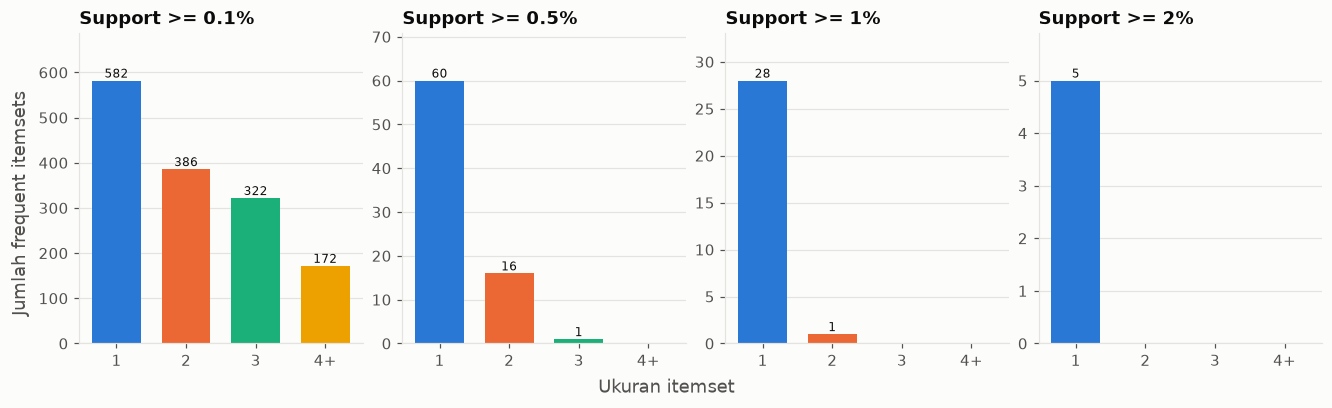

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.6), layout="constrained")
labels = ["1", "2", "3", "4+"]
columns = ["n_frequent_1", "n_frequent_2", "n_frequent_3", "n_frequent_4plus"]
for ax, row in zip(axes, summary.itertuples(index=False)):
    values = [getattr(row, column) for column in columns]
    ax.bar(labels, values, color=SERIES[:4], width=0.7)
    ax.set_title(f"Support >= {row.min_support_pct}%")
    ax.set_ylim(0, max(values) * 1.18 if max(values) else 1)
    for x, count in enumerate(values):
        if count:
            ax.text(x, count, str(count), ha="center", va="bottom", fontsize=8)
    ax.grid(axis="x", visible=False)
fig.supylabel("Jumlah frequent itemsets", color=TEXT_MUTED)
fig.supxlabel("Ukuran itemset", color=TEXT_MUTED)
save(fig, "04_apriori_itemset_counts")
plt.show()

### Hingga sepuluh itemset dengan support tertinggi per eksperimen

Tabel berikut memuat hingga sepuluh itemset dengan support tertinggi pada setiap minimum support. Karena support pasangan tidak bisa melebihi support item tunggalnya, daftar keseluruhan cenderung berisi venue tunggal. Sepuluh pasangan dan tripel teratas juga disimpan terpisah di `results/tables/`.

In [4]:
for support_pct in SUPPORT_LEVELS:
    label = support_pct.replace(".", "p")
    print(f"Minimum support {support_pct}%")
    display(pd.read_csv(config.TABLES_DIR / f"apriori_top10_itemsets_{label}pct.csv")
            [["itemset", "size", "support_count", "support_pct"]])

Minimum support 0.1%


,itemset,size,support_count,support_pct
0,"[""nips""]",1,57358,3.156282
1,"[""aaai""]",1,44683,2.458805
2,"[""icassp""]",1,41063,2.259604
3,"[""embc""]",1,39311,2.163196
4,"[""hci""]",1,37845,2.082525
5,"[""igarss""]",1,35207,1.937362
6,"[""cvpr""]",1,34940,1.922670
7,"[""emnlp""]",1,33355,1.835451
8,"[""icml""]",1,31659,1.742123
9,"[""iros""]",1,31178,1.715655


Minimum support 0.5%


,itemset,size,support_count,support_pct
0,"[""nips""]",1,57358,3.156282
1,"[""aaai""]",1,44683,2.458805
2,"[""icassp""]",1,41063,2.259604
3,"[""embc""]",1,39311,2.163196
4,"[""hci""]",1,37845,2.082525
5,"[""igarss""]",1,35207,1.937362
6,"[""cvpr""]",1,34940,1.922670
7,"[""emnlp""]",1,33355,1.835451
8,"[""icml""]",1,31659,1.742123
9,"[""iros""]",1,31178,1.715655


Minimum support 1%


,itemset,size,support_count,support_pct
0,"[""nips""]",1,57358,3.156282
1,"[""aaai""]",1,44683,2.458805
2,"[""icassp""]",1,41063,2.259604
3,"[""embc""]",1,39311,2.163196
4,"[""hci""]",1,37845,2.082525
5,"[""igarss""]",1,35207,1.937362
6,"[""cvpr""]",1,34940,1.922670
7,"[""emnlp""]",1,33355,1.835451
8,"[""icml""]",1,31659,1.742123
9,"[""iros""]",1,31178,1.715655


Minimum support 2%


,itemset,size,support_count,support_pct
0,"[""nips""]",1,57358,3.156282
1,"[""aaai""]",1,44683,2.458805
2,"[""icassp""]",1,41063,2.259604
3,"[""embc""]",1,39311,2.163196
4,"[""hci""]",1,37845,2.082525


### Kombinasi venue yang paling sering muncul bersama

Tabel pasangan dan tripel berikut menampilkan pola yang tertutup oleh itemset tunggal pada daftar sepuluh teratas keseluruhan. Hasil lengkap tersedia pada CSV eksperimen.

In [5]:
for name in ("pairs", "triples"):
    print(f"Top 10 {name} at 0.1% support")
    display(pd.read_csv(config.TABLES_DIR / f"apriori_top10_{name}_0p1pct.csv")
            [["itemset", "support_count", "support_pct"]])

Top 10 pairs at 0.1% support


,itemset,support_count,support_pct
0,"[""icml"", ""nips""]",18423,1.013776
1,"[""iclr"", ""nips""]",17514,0.963756
2,"[""aaai"", ""nips""]",15761,0.867292
3,"[""acl"", ""emnlp""]",14397,0.792234
4,"[""cvpr"", ""nips""]",14138,0.777982
5,"[""cvpr"", ""iccv""]",13601,0.748432
6,"[""iclr"", ""icml""]",12713,0.699568
7,"[""icra"", ""iros""]",11859,0.652574
8,"[""cvpr"", ""eccv""]",11087,0.610093
9,"[""aaai"", ""ijcai""]",11020,0.606406


Top 10 triples at 0.1% support


,itemset,support_count,support_pct
0,"[""iclr"", ""icml"", ""nips""]",10273,0.565300
1,"[""cvpr"", ""iccv"", ""nips""]",7859,0.432463
2,"[""aaai"", ""icml"", ""nips""]",7516,0.413589
3,"[""cvpr"", ""eccv"", ""iccv""]",7426,0.408636
4,"[""aaai"", ""iclr"", ""nips""]",7217,0.397135
5,"[""aaai"", ""cvpr"", ""nips""]",6811,0.374794
6,"[""cvpr"", ""iclr"", ""nips""]",6641,0.365439
7,"[""cvpr"", ""eccv"", ""nips""]",6526,0.359111
8,"[""aaai"", ""cvpr"", ""iccv""]",6041,0.332423
9,"[""acl"", ""emnlp"", ""naacl""]",5957,0.327800


Pada minimum support 0,1%, terdapat 1.462 frequent itemsets: 582 item tunggal, 386 pasangan, 322 tripel, dan 172 itemset berukuran lebih besar. Pasangan tersering adalah ICML-NeurIPS (`icml`, `nips`): 18.423 penulis atau 1,014% transaksi. Tripel teratas ialah ICLR-ICML-NeurIPS: 10.273 penulis atau 0,565%. CVPR-ICCV dan ACL-EMNLP juga termasuk pasangan yang sering muncul.

Ketika minimum support dinaikkan, jumlah itemset turun menjadi 77 pada 0,5%, 29 pada 1%, dan 5 pada 2%. Hanya ICML-NeurIPS yang tetap menjadi frequent pair pada 1%; tidak ada pasangan yang lolos pada 2%. Perubahan ini berasal dari ambang pemilihan, bukan dari perubahan data transaksi.

## 3. Association rules

Untuk rule `A -> B`, `support = count(A gabung B) / N`, `confidence = count(A gabung B) / count(A)`, dan `lift = confidence / support(B)`. Rule dibangkitkan dari setiap frequent itemset berukuran minimal dua, dengan antecedent dan consequent yang tidak kosong dan tidak beririsan. Rule kemudian disaring pada **confidence minimal 50%**. Lift di atas 1 berarti pola gabungan lebih sering dibandingkan harapan jika kedua sisi independen. Ini tidak menunjukkan sebab-akibat maupun urutan waktu.

In [6]:
for support_pct in SUPPORT_LEVELS:
    label = support_pct.replace(".", "p")
    rules = pd.read_csv(config.EXPERIMENTS_DIR / f"apriori_rules_{label}pct.csv")
    print(f"Minimum support {support_pct}%: {len(rules)} rules; top lift")
    if rules.empty:
        print("No rule meets the thresholds.")
    else:
        display(rules.head(10)[["antecedent", "consequent", "support_count",
                                "support_pct", "confidence_pct", "lift"]])

Minimum support 0.1%: 1225 rules; top lift


,antecedent,consequent,support_count,support_pct,confidence_pct,lift
0,"[""iclr"", ""naacl""]","[""acl"", ""emnlp"", ""nips""]",1885,0.103727,51.028695,155.722354
1,"[""cvpr"", ""eccv"", ""icml""]","[""iccv"", ""iclr""]",1832,0.100811,55.297314,153.701243
2,"[""aaai"", ""eccv"", ""iclr""]","[""cvpr"", ""iccv"", ""nips""]",1865,0.102627,65.738456,152.009410
3,"[""emnlp"", ""naacl"", ""nips""]","[""acl"", ""iclr""]",1885,0.103727,54.495519,149.664197
4,"[""aaai"", ""iccv"", ""iclr""]","[""cvpr"", ""eccv"", ""nips""]",1865,0.102627,53.285714,148.382261
5,"[""eccv"", ""icml"", ""nips""]","[""iccv"", ""iclr""]",1838,0.101141,52.861662,146.931246
6,"[""acl"", ""naacl"", ""nips""]","[""emnlp"", ""iclr""]",1885,0.103727,56.657650,144.063192
7,"[""aaai"", ""cvpr"", ""iccv"", ""iclr""]","[""eccv"", ""nips""]",1865,0.102627,64.599931,141.218806
8,"[""aaai"", ""cvpr"", ""eccv"", ""nips""]","[""iccv"", ""iclr""]",1865,0.102627,50.789760,141.172306
9,"[""eccv"", ""iccv"", ""icml""]","[""cvpr"", ""iclr""]",1832,0.100811,65.498749,137.509916


Minimum support 0.5%: 7 rules; top lift


,antecedent,consequent,support_count,support_pct,confidence_pct,lift
0,"[""icml"", ""nips""]","[""iclr""]",10273,0.565300,55.761819,33.956840
1,"[""iclr"", ""nips""]","[""icml""]",10273,0.565300,58.655932,33.669217
2,"[""eccv""]","[""cvpr""]",11087,0.610093,61.078669,31.767638
3,"[""iccv""]","[""cvpr""]",13601,0.748432,56.442711,29.356429
4,"[""iclr"", ""icml""]","[""nips""]",10273,0.565300,80.807048,25.601977
5,"[""iclr""]","[""nips""]",17514,0.963756,58.689096,18.594379
6,"[""icml""]","[""nips""]",18423,1.013776,58.191983,18.436880


Minimum support 1%: 1 rules; top lift


,antecedent,consequent,support_count,support_pct,confidence_pct,lift
0,"[""icml""]","[""nips""]",18423,1.013776,58.191983,18.43688


Minimum support 2%: 0 rules; top lift
No rule meets the thresholds.


### Rule satu venue ke satu venue

Rule dengan lift tertinggi pada ambang 0,1% sering memuat beberapa venue di masing-masing sisi. Tabel berikut hanya menampilkan antecedent dan consequent yang masing-masing berisi satu venue agar lebih mudah diinterpretasikan. Ini adalah tampilan dari hasil Apriori yang sama.

,antecedent,consequent,support_count,support_pct,confidence_pct,lift
0,"[""ecoc""]","[""ofc""]",4528,0.249166,66.470934,79.943945
1,"[""asru""]","[""interspeech""]",1961,0.107909,72.764378,74.200190
2,"[""eacl""]","[""acl""]",2832,0.155839,60.255319,37.299412
3,"[""corl""]","[""icra""]",2084,0.114678,58.147321,37.033993
4,"[""ACMdis""]","[""chi""]",3163,0.174053,55.784832,34.228931
5,"[""eacl""]","[""emnlp""]",2894,0.159250,61.574468,33.547332
6,"[""naacl""]","[""acl""]",7453,0.410122,53.296625,32.991822
7,"[""3dim""]","[""cvpr""]",1850,0.101801,61.748999,32.116283
8,"[""eccv""]","[""cvpr""]",11087,0.610093,61.078669,31.767638
9,"[""ijcnlp""]","[""acl""]",1840,0.101251,51.068554,31.612595


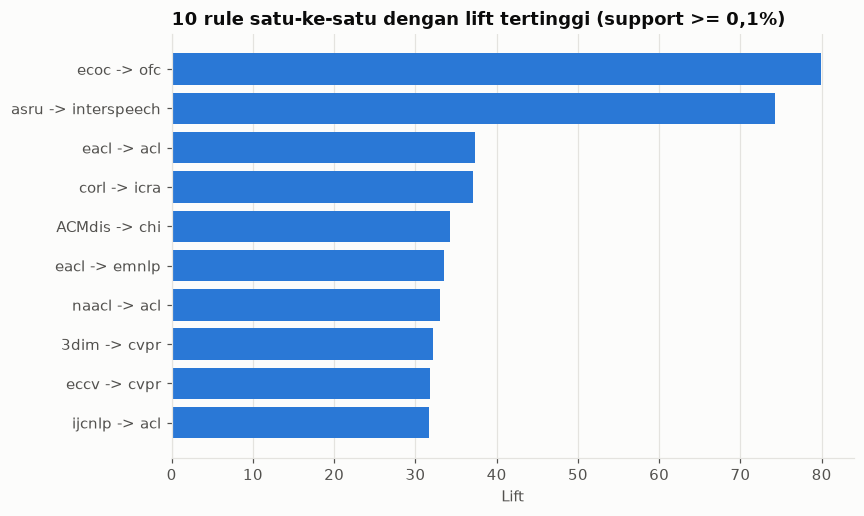

In [7]:
pair_rules = pd.read_csv(config.TABLES_DIR / "apriori_top10_pair_rules_0p1pct.csv")
display(pair_rules[["antecedent", "consequent", "support_count",
                    "support_pct", "confidence_pct", "lift"]])
labels = [f"{a[2:-2]} -> {b[2:-2]}" for a, b in zip(pair_rules["antecedent"], pair_rules["consequent"])]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(labels[::-1], pair_rules["lift"].iloc[::-1], color=SERIES[0])
ax.set_xlabel("Lift")
ax.set_title("10 rule satu-ke-satu dengan lift tertinggi (support >= 0,1%)")
ax.grid(axis="y", visible=False)
save(fig, "05_apriori_pair_rule_lift")
plt.show()

### Interpretasi

- Rule dengan support terbesar pada ambang 0,1% adalah `ICML -> NeurIPS`: 18.423 penulis memiliki riwayat pada kedua venue (support 1,014%), confidence 58,19%, dan lift 18,44.
- Lift tertinggi secara keseluruhan pada ambang 0,1% adalah `ICLR, NAACL -> ACL, EMNLP, NeurIPS` (155,72), tetapi support gabungannya hanya 0,104%, dekat dengan ambang minimum. Consequent yang terdiri dari tiga venue memiliki prevalensi dasar rendah, sehingga lift menjadi tinggi. Rule kompleks seperti ini perlu dibaca bersama support dan confidence-nya.
- Di antara rule satu-ke-satu, `ECOC -> OFC` memiliki lift 79,94, confidence 66,47%, dan support 0,249%. Jadi, venue dengan support tinggi tidak otomatis membentuk rule dengan lift tertinggi.
- Pada minimum support 0,5% tersisa tujuh rule; pada 1% hanya `ICML -> NeurIPS`; pada 2% tidak ada frequent pair sehingga tidak ada rule.

Transaksi menggabungkan riwayat publikasi penulis sepanjang 2015-2025. Rule menunjukkan venue yang muncul bersama dalam riwayat tersebut, bukan bahwa publikasi pada satu konferensi terjadi lebih dulu atau menyebabkan publikasi pada konferensi lain. Keterbatasan identitas penulis berbasis nama dan cakupan DBLP diwarisi dari Task 1.